Import data

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving WA_Fn-UseC_-Telco-Customer-Churn.xlsx to WA_Fn-UseC_-Telco-Customer-Churn.xlsx


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

file = "WA_Fn-UseC_-Telco-Customer-Churn.xlsx"

df = pd.read_excel(file)

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Check data

In [ ]:
df.shape

(7043, 21)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


Clean TotalCharges

In [ ]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

Check missing values:

In [ ]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


Overall churn analysis

In [ ]:
total_customers = len(df)

churned = (df["Churn"] == "Yes").sum()

retained = (df["Churn"] == "No").sum()

churn_rate = churned / total_customers

retention_rate = retained / total_customers

print("Total Customers:", total_customers)
print("Churned:", churned)
print("Retained:", retained)
print("Churn Rate:", churn_rate)
print("Retention Rate:", retention_rate)

Total Customers: 7043
Churned: 1869
Retained: 5174
Churn Rate: 0.2653698707936959
Retention Rate: 0.7346301292063041


Churn by contract

In [ ]:
contract_churn = (
    df.groupby("Contract")
      .agg(
          Customers=("customerID", "count"),
          Churned=("Churn", lambda x: (x == "Yes").sum())
      )
)

contract_churn["Churn_Rate"] = (
    contract_churn["Churned"] /
    contract_churn["Customers"]
)

contract_churn

,Customers,Churned,Churn_Rate
Contract,,,
Month-to-month,3875,1655,0.427097
One year,1473,166,0.112695
Two year,1695,48,0.028319


Visualization of churn

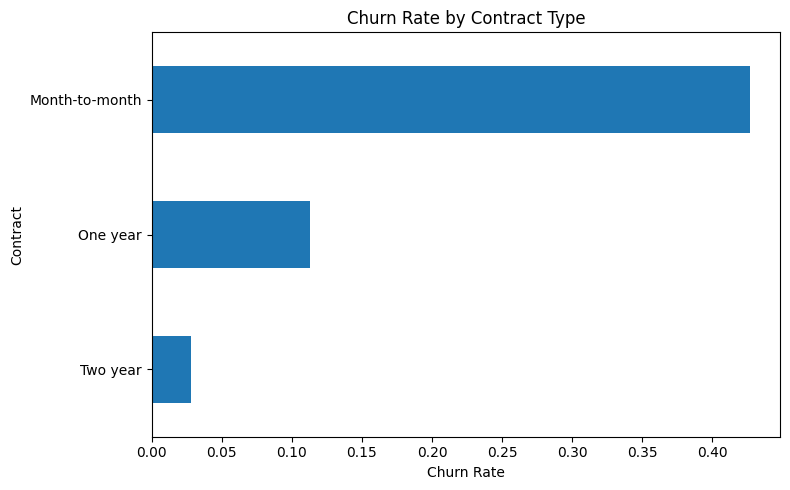

In [ ]:
contract_churn["Churn_Rate"].sort_values().plot(
    kind="barh",
    figsize=(8,5)
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Churn Rate")
plt.ylabel("Contract")

plt.tight_layout()
plt.show()

Churn by tenure

In [ ]:
bins = [0, 3, 6, 12, 24, 36, 48, 60, 72]

labels = [
    "0-3",
    "4-6",
    "7-12",
    "13-24",
    "25-36",
    "37-48",
    "49-60",
    "61-72"
]

df["Tenure_Band"] = pd.cut(
    df["tenure"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

Calculate churn

In [ ]:
tenure_churn = (
    df.groupby("Tenure_Band", observed=False)
      .agg(
          Customers=("customerID", "count"),
          Churned=("Churn", lambda x: (x == "Yes").sum())
      )
)

tenure_churn["Churn_Rate"] = (
    tenure_churn["Churned"] /
    tenure_churn["Customers"]
)

tenure_churn

,Customers,Churned,Churn_Rate
Tenure_Band,,,
0-3,1062,597,0.562147
4-6,419,187,0.446301
7-12,705,253,0.358865
13-24,1024,294,0.287109
25-36,832,180,0.216346
37-48,762,145,0.190289
49-60,832,120,0.144231
61-72,1407,93,0.066098


Plot

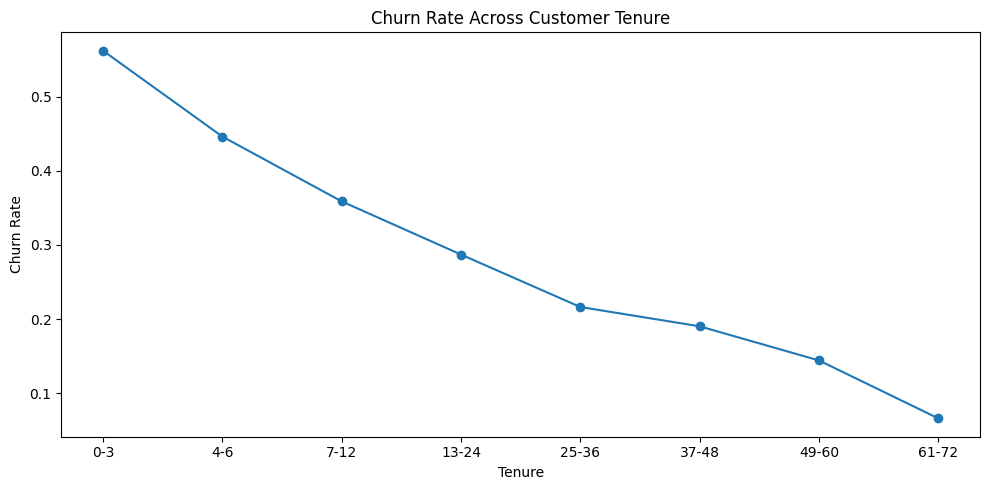

In [ ]:
tenure_churn["Churn_Rate"].plot(
    kind="line",
    marker="o",
    figsize=(10,5)
)

plt.title("Churn Rate Across Customer Tenure")
plt.xlabel("Tenure")
plt.ylabel("Churn Rate")

plt.tight_layout()
plt.show()

Churn by monthly charges

In [ ]:
bins = [0, 40, 60, 80, 100, 150]

labels = [
    "< $40",
    "$40-$60",
    "$60-$80",
    "$80-$100",
    "$100+"
]

df["Charge_Band"] = pd.cut(
    df["MonthlyCharges"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

In [ ]:
charge_churn = (
    df.groupby("Charge_Band", observed=False)
      .agg(
          Customers=("customerID", "count"),
          Churned=("Churn", lambda x: (x == "Yes").sum())
      )
)

charge_churn["Churn_Rate"] = (
    charge_churn["Churned"] /
    charge_churn["Customers"]
)

charge_churn

,Customers,Churned,Churn_Rate
Charge_Band,,,
< $40,1838,214,0.116431
$40-$60,1080,276,0.255556
$60-$80,1459,473,0.324195
$80-$100,1764,653,0.370181
$100+,902,253,0.280488


Identify potential retention drivers

In [ ]:
features = [
    "Contract",
    "InternetService",
    "PaymentMethod",
    "SeniorCitizen",
    "Partner",
    "Dependents",
    "PaperlessBilling",
    "TechSupport",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection"
]

for col in features:

    result = (
        df.groupby(col)["Churn"]
          .apply(lambda x: (x == "Yes").mean())
          .sort_values(ascending=False)
    )

    print("\n", col)
    print(result)


 Contract
Contract
Month-to-month    0.427097
One year          0.112695
Two year          0.028319
Name: Churn, dtype: float64

 InternetService
InternetService
Fiber optic    0.418928
DSL            0.189591
No             0.074050
Name: Churn, dtype: float64

 PaymentMethod
PaymentMethod
Electronic check             0.452854
Mailed check                 0.191067
Bank transfer (automatic)    0.167098
Credit card (automatic)      0.152431
Name: Churn, dtype: float64

 SeniorCitizen
SeniorCitizen
1    0.416813
0    0.236062
Name: Churn, dtype: float64

 Partner
Partner
No     0.329580
Yes    0.196649
Name: Churn, dtype: float64

 Dependents
Dependents
No     0.312791
Yes    0.154502
Name: Churn, dtype: float64

 PaperlessBilling
PaperlessBilling
Yes    0.335651
No     0.163301
Name: Churn, dtype: float64

 TechSupport
TechSupport
No                     0.416355
Yes                    0.151663
No internet service    0.074050
Name: Churn, dtype: float64

 OnlineSecurity
OnlineSecurity
N